# Data viewer

Overview of the data sets for Problem 1 and Problem 2.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style: validated categorical palette, recessive grid and axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RED, MID_GRAY = "#e34948", "#f0efec"
TEXT, TEXT_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": TEXT_2, "axes.labelcolor": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "axes.titlelocation": "left",
})
# Diverging colour map for correlations: blue <-> gray midpoint <-> red.
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, MID_GRAY, RED])

## 1. Problem 1: `task1_lice_forecast.npz`

One row per site and anchor year (2018–2024); the label `y` is 1 if the site breaches the lice limit in the following two years.

In [5]:
import numpy as np

# Load the archive
data = np.load("../data/task1_lice_forecast.npz")

X_registry = data['X_registry']  # facility + geography
X_full = data['X_full']  # registry + lice history
y = data['y']  # breach_next label (0/1)
feature_names_registry = data['feature_names_registry']  # names for X_registry
feature_names_full = data['feature_names_full']  # names for X_full
groups = data['groups']  # siteNumber, for group-aware splits
anchor_year = data['anchor_year']  # anchor year Y of each row

### 1.1 Shapes and first rows

3,116 rows from 496 sites; `X_registry` has 28 features, `X_full` adds 3 lice-history features.

In [6]:
print("X_registry:", X_registry.shape)
print("X_full:    ", X_full.shape)
print("y:         ", y.shape, "| sites:", len(np.unique(groups)),
      "| anchor years:", anchor_year.min(), "-", anchor_year.max())

df1 = pd.DataFrame(X_full, columns=feature_names_full)
df1.insert(0, "site", groups)
df1.insert(1, "anchor_year", anchor_year)
df1["y"] = y
df1.head()

X_registry: (3116, 28)
X_full:     (3116, 31)
y:          (3116,) | sites: 496 | anchor years: 2018 - 2024


,site,anchor_year,productionUnitsMax,productionUnitsPresent,n_conformity_items,n_open_nonconformities,worst_nonconformity_rank,n_rafts,n_enclosures,n_floaters,...,area_Ryfylke,area_Stadt til Hustadvika,area_Svenskegrensen til Jæren,area_Vest-Finnmark,area_Vestfjorden og Vesterålen,area_Øst-Finnmark,past_mean_af,past_frac_above,past_n_weeks,y
0,10050,2018,4.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.203067,0.013333,75.0,0
1,10054,2018,8.0,NaN,0.0,0.0,0.0,1.0,3.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.212971,0.014493,138.0,0
2,10086,2018,3.0,2.0,1.0,1.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.239918,0.040984,122.0,0
3,10110,2018,10.0,4.0,1.0,1.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.104683,0.000000,126.0,0
4,10136,2018,13.0,3.0,0.0,0.0,0.0,1.0,3.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.111359,0.029126,103.0,0


### 1.2 Summary statistics

In [7]:
df1[list(feature_names_full)].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
productionUnitsMax,3116.0,9.502,3.416,1.000,7.000,10.000,12.000,24.000
productionUnitsPresent,2764.0,3.354,3.197,0.000,1.000,3.000,5.000,15.000
n_conformity_items,3116.0,1.646,3.030,0.000,0.000,1.000,1.000,30.000
n_open_nonconformities,3116.0,1.015,2.464,0.000,0.000,1.000,1.000,30.000
worst_nonconformity_rank,3116.0,0.456,1.078,0.000,0.000,0.000,0.000,3.000
n_rafts,3116.0,1.019,0.492,0.000,1.000,1.000,1.000,5.000
n_enclosures,3116.0,1.798,1.761,0.000,1.000,1.000,2.000,13.000
n_floaters,3116.0,1.501,0.809,0.000,1.000,1.000,2.000,5.000
n_mooring_systems,3116.0,1.844,0.414,1.000,2.000,2.000,2.000,4.000
n_integrated,3116.0,0.058,0.234,0.000,0.000,0.000,0.000,1.000


### 1.3 Missing values

Only `productionUnitsPresent` is missing (352 rows, 11%).

In [8]:
n_missing = df1[list(feature_names_full)].isna().sum()
print(n_missing[n_missing > 0])
print(f"fraction missing: {n_missing.max() / len(df1):.3f}")

missing = df1["productionUnitsPresent"].isna()
print(f"positive rate when missing: {y[missing].mean():.3f}, "
      f"when present: {y[~missing].mean():.3f}")

productionUnitsPresent    352
dtype: int64
fraction missing: 0.113
positive rate when missing: 0.227, when present: 0.184


### 1.4 Label distribution

589 breachers (19%); the positive rate varies between 13% and 26% across anchor years.

y = 0 (no breach): 2527  |  y = 1 (breach): 589  |  positive rate: 0.189


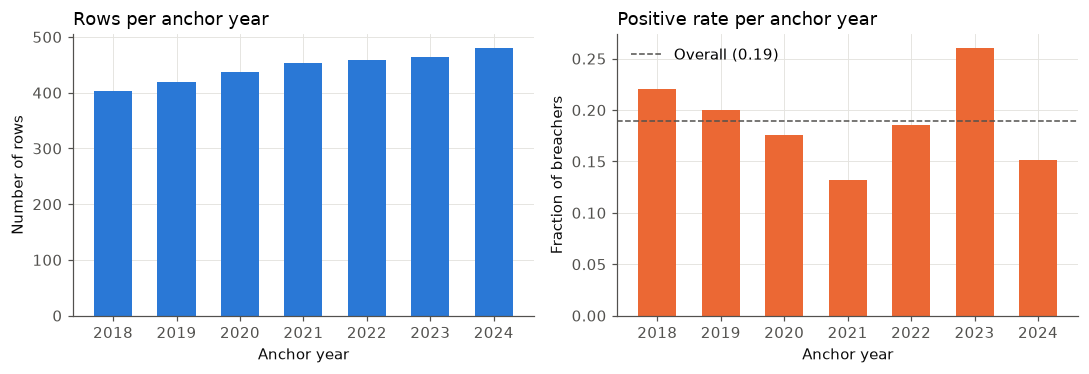

In [9]:
counts = np.bincount(y)
print(f"y = 0 (no breach): {counts[0]}  |  y = 1 (breach): {counts[1]}  |  "
      f"positive rate: {y.mean():.3f}")

years = np.unique(anchor_year)
rows_per_year = [np.sum(anchor_year == a) for a in years]
rate_per_year = [y[anchor_year == a].mean() for a in years]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(years, rows_per_year, color=BLUE, width=0.6)
axes[0].set_title("Rows per anchor year")
axes[0].set_xlabel("Anchor year"); axes[0].set_ylabel("Number of rows")

axes[1].bar(years, rate_per_year, color=ORANGE, width=0.6)
axes[1].axhline(y.mean(), color=TEXT_2, lw=1, ls="--", label=f"Overall ({y.mean():.2f})")
axes[1].set_title("Positive rate per anchor year")
axes[1].set_xlabel("Anchor year"); axes[1].set_ylabel("Fraction of breachers")
axes[1].legend()
fig.tight_layout()

### 1.5 Rows per site

Sites have 1–7 rows, so the data must be split by site.

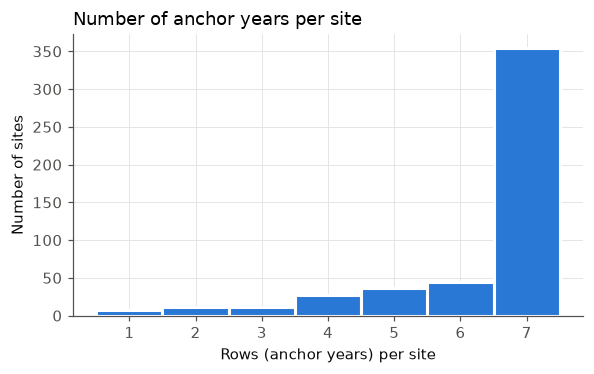

In [10]:
_, rows_per_site = np.unique(groups, return_counts=True)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.hist(rows_per_site, bins=np.arange(0.5, rows_per_site.max() + 1.5), color=BLUE,
        edgecolor="white", linewidth=2)
ax.set_title("Number of anchor years per site")
ax.set_xlabel("Rows (anchor years) per site"); ax.set_ylabel("Number of sites")
fig.tight_layout()

### 1.6 Lice-history features by class

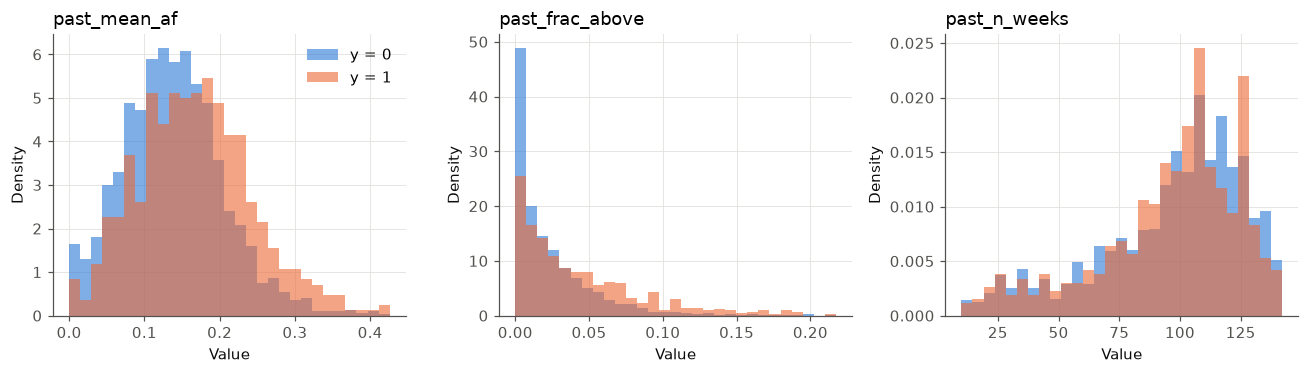

In [11]:
lice_features = ["past_mean_af", "past_frac_above", "past_n_weeks"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, name in zip(axes, lice_features):
    x = df1[name].values
    bins = np.linspace(x.min(), np.quantile(x, 0.99), 30)   # clip extreme 1% for readability
    ax.hist(x[y == 0], bins=bins, density=True, alpha=0.6, color=BLUE, label="y = 0")
    ax.hist(x[y == 1], bins=bins, density=True, alpha=0.6, color=ORANGE, label="y = 1")
    ax.set_title(name); ax.set_xlabel("Value"); ax.set_ylabel("Density")
axes[0].legend()
fig.tight_layout()

### 1.7 Registry features by class

Class means after z-scoring each feature.

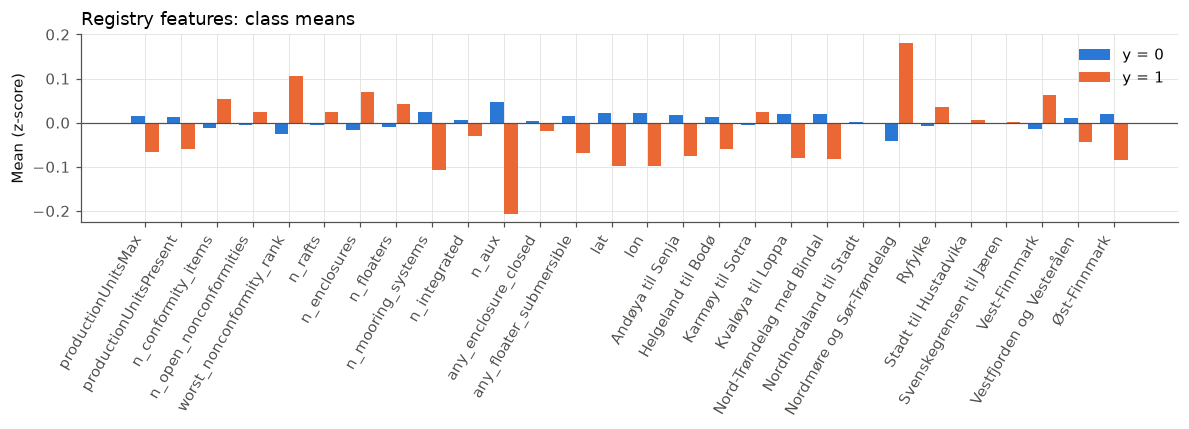

In [12]:
registry = df1[list(feature_names_registry)]
z = (registry - registry.mean()) / registry.std()
means = pd.DataFrame({"y = 0": z[y == 0].mean(), "y = 1": z[y == 1].mean()})

fig, ax = plt.subplots(figsize=(11, 4))
xpos = np.arange(len(means))
ax.bar(xpos - 0.2, means["y = 0"], 0.38, color=BLUE, label="y = 0")
ax.bar(xpos + 0.2, means["y = 1"], 0.38, color=ORANGE, label="y = 1")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels([n.replace("area_", "") for n in means.index], rotation=60, ha="right")
ax.set_ylabel("Mean (z-score)")
ax.set_title("Registry features: class means")
ax.legend()
fig.tight_layout()

### 1.8 Production areas

The positive rate ranges from 0% (Øst-Finnmark) to 28% (Nordmøre og Sør-Trøndelag).

,rows,positive_rate
area,,
Øst-Finnmark,22,0.000
Nord-Trøndelag med Bindal,206,0.131
Kvaløya til Loppa,205,0.132
Andøya til Senja,188,0.133
Helgeland til Bodø,287,0.153
Vestfjorden og Vesterålen,361,0.166
Nordhordaland til Stadt,378,0.188
Svenskegrensen til Jæren,21,0.190
Stadt til Hustadvika,123,0.195


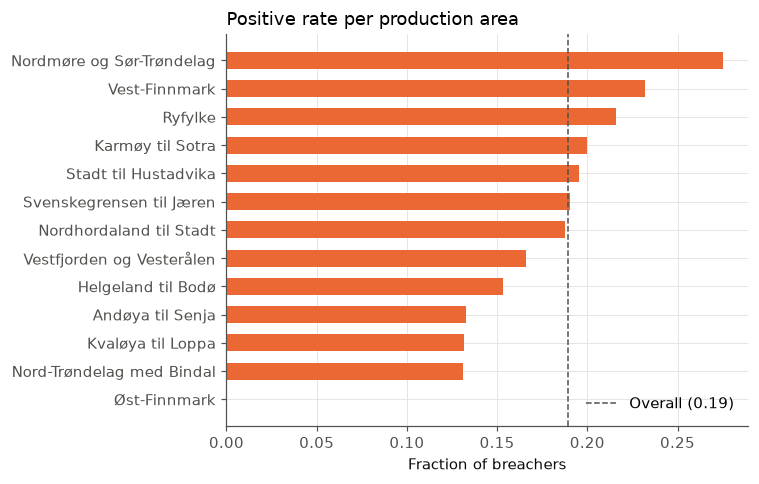

In [13]:
area_cols = [n for n in feature_names_full if n.startswith("area_")]
area_of_row = np.array(area_cols)[np.argmax(df1[area_cols].values, axis=1)]
area_table = (pd.DataFrame({"area": [a.replace("area_", "") for a in area_of_row], "y": y})
              .groupby("area")["y"].agg(rows="size", positive_rate="mean")
              .sort_values("positive_rate"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(area_table.index, area_table["positive_rate"], color=ORANGE, height=0.6)
ax.axvline(y.mean(), color=TEXT_2, lw=1, ls="--", label=f"Overall ({y.mean():.2f})")
ax.set_xlabel("Fraction of breachers"); ax.set_title("Positive rate per production area")
ax.legend(loc="lower right")
fig.tight_layout()
area_table.round(3)

### 1.9 Site locations

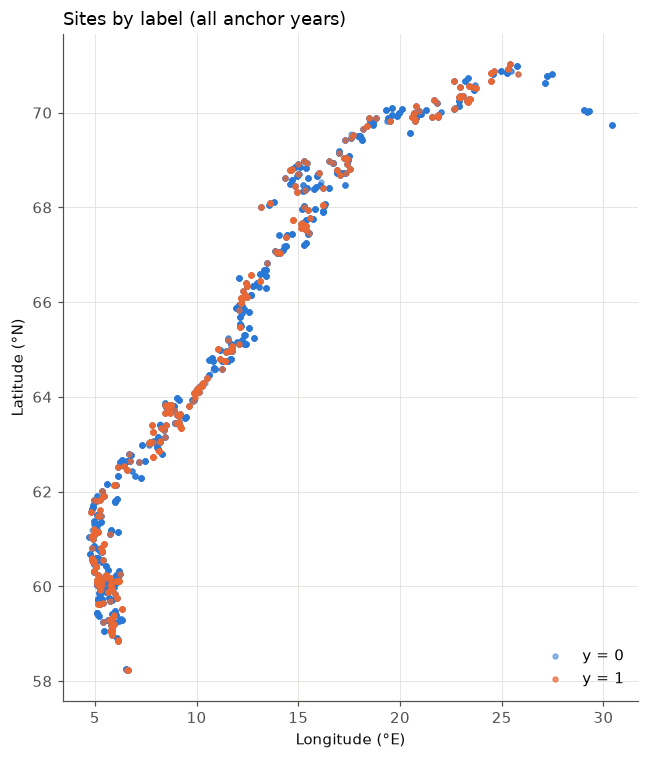

In [14]:
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(df1["lon"][y == 0], df1["lat"][y == 0], s=10, color=BLUE, alpha=0.5, label="y = 0")
ax.scatter(df1["lon"][y == 1], df1["lat"][y == 1], s=10, color=ORANGE, alpha=0.7, label="y = 1")
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Sites by label (all anchor years)")
ax.legend(loc="lower right")
fig.tight_layout()

### 1.10 Feature–label correlation

`past_frac_above` has the strongest correlation with the label.

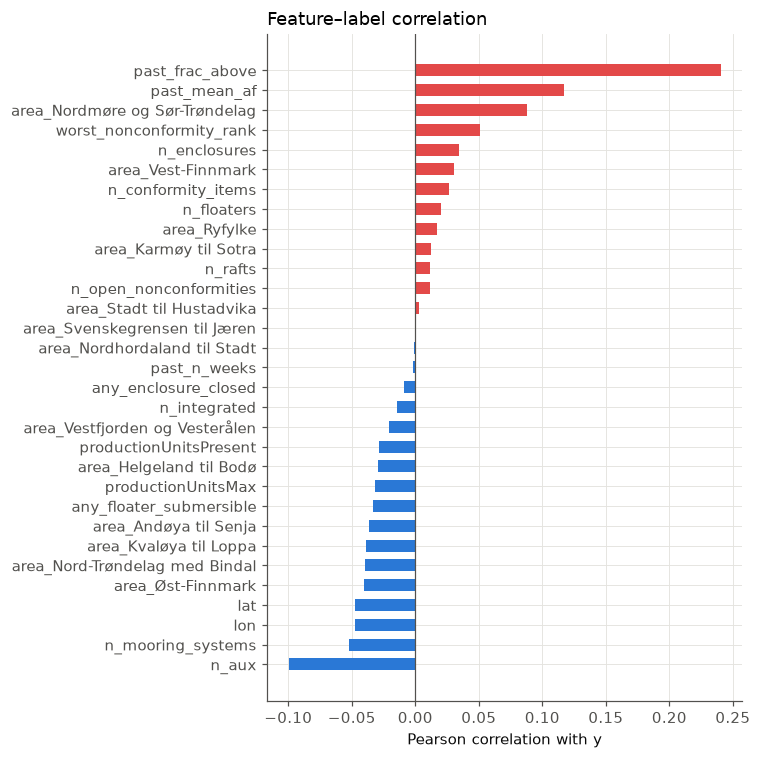

In [15]:
corr_y = df1[list(feature_names_full)].corrwith(df1["y"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(corr_y.index, corr_y.values, color=[RED if v > 0 else BLUE for v in corr_y.values], height=0.6)
ax.axvline(0, color=TEXT_2, lw=0.8)
ax.set_xlabel("Pearson correlation with y")
ax.set_title("Feature–label correlation")
fig.tight_layout()

## 2. Problem 2: `task2_water_reports.npz`

Eight water-quality measurements per water supply system: 915 reference and 246 query records, no missing values and no labels.

In [16]:
data2 = np.load("../data/task2_water_reports.npz")

X_reference = data2["X_reference"]                          # learn normal structure
feature_names_reference = data2["feature_names_reference"]  # column names
X_query = data2["X_query"]                                  # records to inspect
feature_names_query = data2["feature_names_query"]          # column names
record_ids_query = data2["record_ids_query"]                # ids, for reporting

print("X_reference:", X_reference.shape, "| X_query:", X_query.shape)
print("same columns:", np.array_equal(feature_names_reference, feature_names_query))
print("missing values:", np.isnan(X_reference).sum(), "/", np.isnan(X_query).sum())

df_ref = pd.DataFrame(X_reference, columns=feature_names_reference)
df_qry = pd.DataFrame(X_query, columns=feature_names_query, index=record_ids_query)
df_qry.head()

X_reference: (915, 8) | X_query: (246, 8)
same columns: True
missing values: 0 / 0


,conductivity,sodium,chloride,sulfate,ph,color,turbidity,toc
Wcce00ce311e8,5.395,5.80,9.40,1.00,7.2,2.0,0.11,0.50
Wcd28c1a44de1,5.395,2.70,2.00,4.30,7.6,10.0,0.13,2.10
Wcd3158aaec26,260.000,3.40,19.00,33.00,7.5,1.7,0.35,0.71
Wcd513fbc4703,15.200,7.50,20.00,4.80,7.7,3.0,0.10,2.70
Wcdf135a1f55d,3.000,1.72,1.51,2.23,7.3,4.0,0.47,1.80


### 2.1 Summary statistics

In [17]:
summary = pd.concat({"reference": df_ref.describe().T, "query": df_qry.describe().T}, axis=1)
summary.loc[:, (slice(None), ["mean", "50%", "std", "min", "max"])].round(2)

,reference,query,reference,query,reference,query,reference,query,reference,query
,mean,mean,50%,50%,std,std,min,min,max,max
conductivity,11.29,24.62,8.30,9.02,10.18,47.72,0.00,0.11,92.70,317.00
sodium,8.74,9.19,4.40,4.86,14.98,20.87,0.00,0.00,134.00,260.00
chloride,8.54,9.35,5.18,5.20,13.11,22.34,0.00,0.00,222.00,290.00
sulfate,6.66,8.45,2.87,3.00,11.90,19.96,0.00,0.00,159.00,190.00
ph,7.33,7.34,7.30,7.35,0.58,0.57,5.75,6.10,9.15,8.90
color,5.09,4.16,3.00,3.00,4.81,3.29,0.00,0.00,34.00,19.00
turbidity,0.28,0.27,0.20,0.20,0.81,0.33,0.00,0.00,17.30,4.25
toc,1.39,1.29,1.10,1.00,1.06,0.92,0.00,0.00,12.00,6.70


### 2.2 Feature distributions

Top: raw units (strongly right-skewed). Bottom: `log(1 + x)` for all features except `ph`, as in Appendix B.

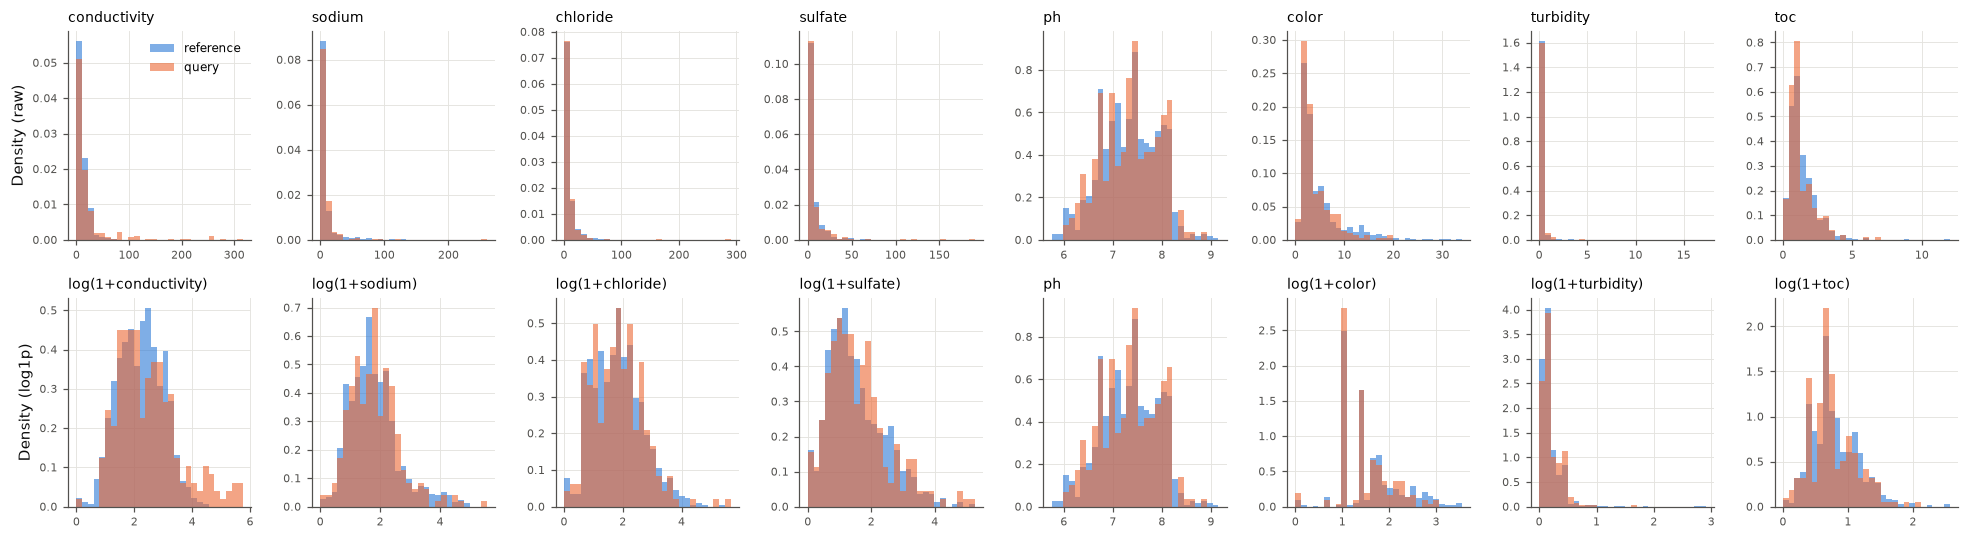

In [18]:
names = list(feature_names_reference)
log_cols = [n for n in names if n != "ph"]
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for j, name in enumerate(names):
    for row, transform in enumerate(("raw", "log1p")):
        ref, qry = df_ref[name].values, df_qry[name].values
        if transform == "log1p" and name in log_cols:
            ref, qry = np.log1p(ref), np.log1p(qry)
        bins = np.linspace(min(ref.min(), qry.min()), max(ref.max(), qry.max()), 30)
        ax = axes[row, j]
        ax.hist(ref, bins=bins, density=True, alpha=0.6, color=BLUE, label="reference")
        ax.hist(qry, bins=bins, density=True, alpha=0.6, color=ORANGE, label="query")
        label = name if transform == "raw" or name == "ph" else f"log(1+{name})"
        ax.set_title(label, fontsize=9)
        ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel("Density (raw)"); axes[1, 0].set_ylabel("Density (log1p)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

### 2.3 Feature correlations

Reference set on the log scale.

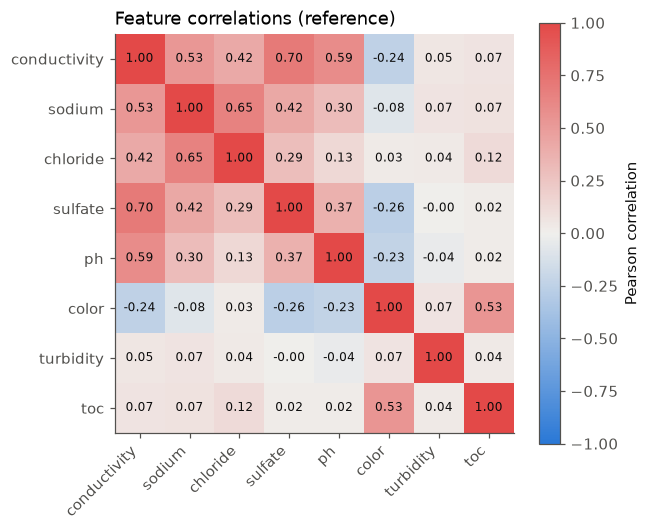

In [19]:
ref_log = df_ref.copy()
ref_log[log_cols] = np.log1p(ref_log[log_cols])
C = ref_log.corr().values

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=8, color=TEXT)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Feature correlations (reference)")
fig.tight_layout()